## Regression

In [3]:
import pandas as pd 
import numpy as np

In [4]:
df= pd.read_csv("powerplant_data.csv")

In [5]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [6]:
# here,
# AT- temprature
# V- vacume
# AP- pressure
# RH- humidity 

# PE- produced energy (Target)

In [7]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [8]:
X=df.drop("PE", axis=1)
y=df["PE"]

In [9]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test= train_test_split(X,y ,random_state=42, test_size=0.2)

In [10]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.fit_transform(X_test)

In [11]:
import torch 
import torch.nn as nn 

X_train_tensor= torch.tensor(X_train_scaled, dtype=torch.float32) # we give here float as it is, also its scaled so now its numpy array so here we can directly acsses the values. 
X_test_tensor= torch.tensor(X_test_scaled, dtype= torch.float32)

y_train_tensor= torch.tensor(y_train.values, dtype= torch.float32).view(-1,1) # here its pandas sereas(not scaled) so to acsess its values we use
# ".values" also we use view to change the shape of the sereas into Pytorche's desired shape (-1) means automaticaly detect rows and (1) says now 
# we want it to have in column format, since y_train is in row format only (7564,). 
y_test_tensor= torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [12]:
# untill know we were having the 4 data catagories in our ram
from torch.utils.data import TensorDataset ,DataLoader 
train_dataset= TensorDataset(X_train_tensor, y_train_tensor) # its (i/p_feature, o/p_feature)
test_dataset= TensorDataset(X_test_tensor, y_test_tensor) # here we have fetched data from ram

In [13]:
train_loader= DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader= DataLoader(test_dataset, batch_size=32)
# know data is ready for training 

## Deep Learning

In [15]:
# Defining ANN model 
class ANN(nn.Module): # Inhereting parent class nn.module
    def __init__(self): 
        super(ANN, self).__init__()  # just one work call the parents class constructor(nn.module)

        self.model= nn.Sequential(  # here nn.sequntial is like a blueprint telling to process 1 at first ,then 2 ,etc...
            # 1st hidden layer , also self.model is variable encapsulating our model and sequntial is a pyotrch container holding our models layers.
            nn.Linear(X_train.shape[1],6), # ".shape[1]", will tell how many features for i/p are there, and 6 there is the o/p feature.
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6,6), # this is a layer of y=6 neurons with x=6 inputs
            nn.ReLU(), # this the activation function giving non-linearity to the model for better line fitting according to the data.
    
            # output layer 
            nn.Linear(6,1),
        )

    def forward(self, x):
        return self.model(x)

In [16]:
# Building our model(object)
import torch.optim as optim # importing optimizers

model= ANN()

# solving regression so using MSE 
criterion= nn.MSELoss() # means mse is the loss function which will be used to make the model better
optimizer= optim.Adam(model.parameters(),lr=0.01) #in pytorch we dont have to initialise weight and bias so we directly pass it here in the optimiser. 

In [17]:
# Trainig the ann ,we will have 100 epoch. 
val_losses= [] # validating the training
train_losses= [] # loss on trainig data 

best_val_loss= float("inf") # initially saved as infinity to later capture the lower loss value.

epochs= 100

for epoch in range(epochs): 
    model.train() #this is to train the model on each epoch.
    # know for each batch in an epoch.
    running_loss= 0.0 # total initial traning loss for one epoch

    for xb ,yb in train_loader:  # know data loader will give the: 
        # xb- Features(i/p) of each batch to train 
        # yb- labels(o/p) of each batch to be tested on.
        optimizer.zero_grad() # optemizer has a tendensy to accumulate the gradient so to set it 0 every time we use it.

        outputs= model(xb) # this will be forward pass ,and getting predicted output. 
        loss= criterion(outputs, yb) # here its given to calculate the loss in this forward pass.
        loss.backward() # backward propog. to compute gradients
        optimizer.step() # parameters updation

        running_loss += loss.item() # since loss is found by pytorch it will be in tenser so converting(using .item()) and storing it.

    epoch_train_loss= running_loss/len(train_loader) # this will tell ous avg. loss.
    train_losses.append(epoch_train_loss)

    # validation(not final test, but just done to see the model is trained in better way, so only needs forwrad propo. no optimizer or backw. propo)
    model.eval() # this will tell torch to stop adjusting the parameters know and just test.
    running_val_loss= 0.0

    with torch.no_grad(): # by default torch has autograd(automaticaly computes geadient)this is to stop it, this saves memory and speeds computation.
        for xb, yb in test_loader: 
            outputs= model(xb) 
            loss= criterion(outputs, yb)
            running_val_loss+= loss.item()

    epoch_val_loss= running_val_loss/len(test_loader) 
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss {epoch_val_loss}")

    if epoch_val_loss < best_val_loss: 
        best_val_loss= epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")

epoch 1/100 ==> train loss = 82457.3622390747 & val loss 4389.254553222656
epoch 2/100 ==> train loss = 1170.6201508839924 & val loss 299.05904591878254
epoch 3/100 ==> train loss = 157.16276568571726 & val loss 72.57243073781332
epoch 4/100 ==> train loss = 48.01807465950648 & val loss 31.79370560646057
epoch 5/100 ==> train loss = 28.83311638236046 & val loss 23.058262475331624
epoch 6/100 ==> train loss = 24.516608091195426 & val loss 22.428582270940144
epoch 7/100 ==> train loss = 23.02470649878184 & val loss 22.01423559188843
epoch 8/100 ==> train loss = 22.634326513608297 & val loss 21.204119777679445
epoch 9/100 ==> train loss = 22.372580655415852 & val loss 21.21837592124939
epoch 10/100 ==> train loss = 21.968783203760783 & val loss 20.351042826970417
epoch 11/100 ==> train loss = 21.681181343396506 & val loss 21.21314810117086
epoch 12/100 ==> train loss = 21.69353294769923 & val loss 23.29645897547404
epoch 13/100 ==> train loss = 21.887244137128196 & val loss 21.20995766321

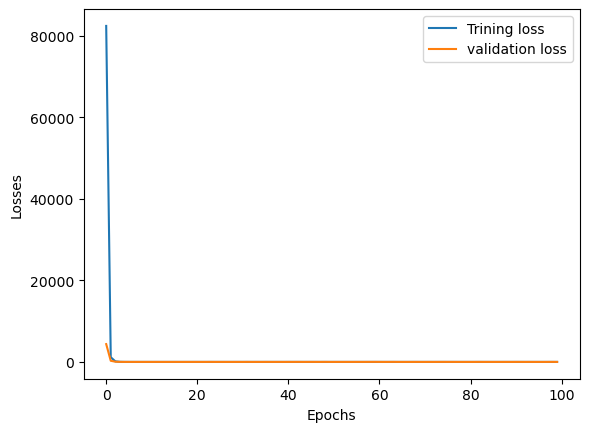

In [18]:
# so what happens here is that the loss is getting reduced but untill a threshold. 
import matplotlib.pyplot as plt

loss_df =pd.DataFrame({
    "Training loss": train_losses, 
    "val_loss": val_losses
})

plt.plot(loss_df["Training loss"], label="Trining loss")
plt.plot(loss_df["val_loss"], label="validation loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [19]:
# loading the best model 
model.load_state_dict(torch.load("best_model.pt")) # loading the best model parameter saved earlier ,to make the final one.

<All keys matched successfully>

In [20]:
# Evaluation
from sklearn.metrics import r2_score

model.eval()
with torch.no_grad(): # saving compute power. 
    train_pred= model(X_train_tensor)
    test_pred= model(X_test_tensor)

    train_mse_loss= criterion(train_pred, y_train_tensor) # (predicted, testing value)
    test_mse_loss= criterion(test_pred, y_test_tensor)

print("Training MSE:",train_mse_loss.item())
print("Testing MSE:",test_mse_loss.item())

print("R2 score:",r2_score(y_test, test_pred))

Training MSE: 19.726476669311523
Testing MSE: 18.208833694458008
R2 score: 0.9363648228715795


In [21]:
predicted_df= pd.DataFrame(test_pred.numpy(),columns=["Pridicted Values"])
actual_df= pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df, actual_df], axis=1)

,Pridicted Values,Actual Values
0,432.901703,433.27
1,435.426880,438.16
2,462.244110,458.42
3,478.486298,480.82
4,434.376526,441.41
...,...,...
1909,450.748230,456.70
1910,431.974243,438.04
1911,467.652740,467.80
1912,433.062103,437.14


## Classification

In [77]:
df1= pd.read_csv("DateFruit_Dataset.csv")

df1.head() # 34 features and 1 class(category) ,also its a multi-class classification

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [79]:
X= df1.drop("Class", axis=1)
y= df1["Class"]

In [81]:
df1["Class"].unique() # means we will have 7 neurons in our o/p layer.

array(['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY'],
      dtype=object)

In [83]:
from sklearn.preprocessing import LabelEncoder

le= LabelEncoder()
y =le.fit_transform(y)

In [85]:
X_train, X_test, y_train, y_test= train_test_split(X,y, random_state=42, test_size=0.2)

In [87]:
X_train_scale= scaler.fit_transform(X_train)
X_test_scale =scaler.fit_transform(X_test)

## ANN

In [90]:
# tensor conversion

X_train_tensor= torch.tensor(X_train_scale, dtype=torch.float32)
X_test_tensor= torch.tensor(X_test_scale, dtype=torch.float32) 

y_train_tensor= torch.tensor(y_train, dtype=torch.long) #"long" format needed to cross entropy loss
y_test_tensor= torch.tensor(y_test, dtype=torch.long)

In [92]:
train_dataset= TensorDataset(X_train_tensor, y_train_tensor)
test_dataset= TensorDataset(X_test_tensor, y_test_tensor)

In [94]:
train_loader= DataLoader(train_dataset, batch_size=32 ,shuffle=True)
test_loader= DataLoader(test_dataset, batch_size=32)

In [96]:
class ANN(nn.Module): 
    def __init__(self): 
        super(ANN, self).__init__()

        self.model= nn.Sequential(
            nn.Linear(X.shape[1], 64), 
            nn.ReLU(), 

            nn.Linear(64, 64), 
            nn.ReLU(),

            nn.Linear(64, 7)
        )
    def forward(self, x):
        return self.model(x)

In [98]:
model= ANN()

criteria= nn.CrossEntropyLoss()
optimizer= optim.Adam(model.parameters())

In [100]:
epochs= 50

for epoch in range(epochs):
    model.train()
    runnig_loss= 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        
        outputs= model(xb) 
        loss= criteria(outputs, yb)
        loss.backward()
        optimizer.step() #updating parameter

        running_loss += loss.item()

    train_loss= running_loss/len(train_loader) # avg. loss per batch in 1 epoch 

    print(f"epoch= {epoch+1}/{epochs}, loss={train_loss}")

epoch= 1/50, loss=241.84001440005935
epoch= 2/50, loss=242.97435437533346
epoch= 3/50, loss=243.69081132245282
epoch= 4/50, loss=244.20178836132348
epoch= 5/50, loss=244.62007388279966
epoch= 6/50, loss=244.98203315620017
epoch= 7/50, loss=245.30450258114243
epoch= 8/50, loss=245.61226863448215
epoch= 9/50, loss=245.89016435459084
epoch= 10/50, loss=246.14282763200438
epoch= 11/50, loss=246.38407326459065
epoch= 12/50, loss=246.6141302297474
epoch= 13/50, loss=246.82362760669986
epoch= 14/50, loss=247.02459345176644
epoch= 15/50, loss=247.22333968983224
epoch= 16/50, loss=247.40140387450052
epoch= 17/50, loss=247.584265746032
epoch= 18/50, loss=247.74776289241296
epoch= 19/50, loss=247.9153142259026
epoch= 20/50, loss=248.07638558277446
epoch= 21/50, loss=248.2285821946596
epoch= 22/50, loss=248.3763331188795
epoch= 23/50, loss=248.51595739179808
epoch= 24/50, loss=248.6536203172721
epoch= 25/50, loss=248.78533874032766
epoch= 26/50, loss=248.91389800002545
epoch= 27/50, loss=249.04704